<a href="https://colab.research.google.com/github/salmanfarsiali/titanic-eda-analysis/blob/main/titanic_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment: Exploratory Data Analysis (EDA) on the Titanic Dataset

This assignment will guide you through a comprehensive Exploratory Data Analysis (EDA) of the famous Titanic disaster dataset. The goal is to understand the dataset's structure, identify patterns, and uncover insights related to passenger survival.


## Dataset
~~~
The dataset includes information such as:

PassengerId: Unique ID for each passenger.

Survived: Survival (0 = No, 1 = Yes) - Target Variable.

Pclass: Ticket class (1 = 1st, 2 = 2nd, 3 = 3rd).

Name: Passenger name.

Sex: Passenger sex.

Age: Age in years.

SibSp: # of siblings/spouses aboard the Titanic.

Parch: # of parents/children aboard the Titanic.

Ticket: Ticket number.

Fare: Passenger fare.

Cabin: Cabin number.
~~~
Embarked: Port of Embarkation (C = Cherbourg, Q = Queenstown, S = Southampton).

The dataset can be found here:

https://github.com/datasciencedojo/datasets/blob/master/titanic.csv

To download this data using terminal, run the following command:

!wget https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv  


## Task 1: Data Loading and Initial Inspection

- Load the dataset (e.g., using pandas in Python).

- Display the first 5 rows to get a quick look at the data structure.

- Check the data types of all columns (.info()).

- Get descriptive statistics of the numerical columns (.describe()).

- Identify the total number of missing values for each column.


## Task 2: Handling Missing Values

Missing data can skew analysis. For this task, you will address the missing values in three key columns: Age, Cabin, and Embarked.

Cabin:
- Calculate the percentage of missing values in the Cabin column.

Decision:
- Do we need to drop the Cabin column entirely from the analysis? Briefly justify your reason.

Embarked:
- Find the most frequent port of embarkation (the mode).Impute the missing values in the Embarked column with the mode.

Age:
- Impute the missing values in the Age column with the median age.



## Task 3: Univariate Analysis
Univariate analysis looks at a single variable at a time.

Survival Rate:
- Calculate the overall survival rate (percentage of passengers who survived).

- Visualize the distribution of the Survived variable (e.g., a count plot/bar chart).

Passenger Class (Pclass):
- Visualize the distribution of Pclass using a count plot.

- Identify which class had the most passengers.

Age Distribution:
- Plot a histogram of the Age column to visualize its distribution.



## Task 4: Bivariate and Multivariate Analysis

Bivariate analysis explores the relationship between two variables, specifically focusing on how other features relate to the target variable (Survived).

Survival by Sex:
- Create a crosstabulation (or a grouped count) to show the count of survivors and non-survivors grouped by Sex.

- Visualize this relationship using a stacked bar chart or a grouped count plot.

- Question: Which gender had a significantly higher survival rate?

Survival by Class (Pclass):
- Calculate and visualize the survival rate for each Pclass.

- Question: Is there a clear correlation between ticket class and survival probability?

Survival by Age:
- Plot and compare the age distribution of survivors vs. non-survivors.

- Observation: What does the plot suggest about the survival chances of children and the elderly?

Survival by Port of Embarkation (Embarked):

- Calculate and visualize the survival rate for each Embarked port.


## Task 5: Conclusion and Insights
Based on your EDA, write a brief (3-5 sentences) conclusion summarizing the most significant factors affecting survival on the Titanic. Highlight the top 2-3 features that appear to be the strongest predictors of survival.

## Task 1: Data Loading and Initial Inspection
- Load the dataset (e.g., using pandas in Python).

- Display the first 5 rows to get a quick look at the data structure.

- Check the data types of all columns (.info()).

- Get descriptive statistics of the numerical columns (.describe()).

- Identify the total number of missing values for each column.



In [ ]:
!wget https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv

--2026-07-20 19:15:20--  https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 60302 (59K) [text/plain]
Saving to: ‘titanic.csv’

titanic.csv         100%[===================>]  58.89K  --.-KB/s    in 0.001s  

2026-07-20 19:15:20 (45.5 MB/s) - ‘titanic.csv’ saved [60302/60302]



In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv("titanic.csv")

In [ ]:
# Display the first 5 rows
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# Check the data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# Get descriptive statistics
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# Identify the total number of missing values
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


## Task 2: Handling Missing Values
Missing data can skew analysis. For this task, you will address the missing values in three key columns: Age, Cabin, and Embarked.

Cabin:

- Calculate the percentage of missing values in the Cabin column.

Decision:
- Do we need to drop the Cabin column entirely from the analysis? Briefly justify your reason.


Embarked:
- Find the most frequent port of embarkation (the mode). Impute the missing values in the Embarked column with the mode.

Age:
- Impute the missing values in the Age column with the median age.



In [ ]:
# Total missing values in Cabin
missing_cabin = df["Cabin"].isnull().sum()

# Percentage of missing values
missing_percentage = (missing_cabin / len(df)) * 100

print("Missing Values in Cabin:", missing_cabin)
print("Percentage of Missing Values:", round(missing_percentage, 2), "%")

Missing Values in Cabin: 687
Percentage of Missing Values: 77.1 %


In [ ]:
# Drop the Cabin Column
df.drop(columns=['Cabin'], inplace=True)

## Decision:
Yes, the Cabin column should be dropped because it contains approximately 77.10% missing values. Since most of the data is unavailable, imputing the missing values would not be reliable. Removing the column helps simplify the analysis and avoids introducing bias into the dataset.

In [ ]:
# Find the most frequent port of embarkation (the mode)

mode_embarked = df["Embarked"].mode()[0]
print("Most Frequent Port of Embarkation:", mode_embarked)

Most Frequent Port of Embarkation: S


In [ ]:
# Impute the missing values with the Mode

df["Embarked"] = df["Embarked"].fillna(mode_embarked)
print(df["Embarked"].isnull().sum())

0


In [ ]:
# Find the Median Age

median_age = df["Age"].median()
print("Median Age:", median_age)

Median Age: 28.0


In [ ]:
# Impute the Missing Values with the Median

df["Age"] = df["Age"].fillna(median_age)
print(df["Age"].isnull().sum())

0


## Task 3: Univariate Analysis
Univariate analysis looks at a single variable at a time.

Survival Rate:
- Calculate the overall survival rate (percentage of passengers who survived).

- Visualize the distribution of the Survived variable (e.g., a count plot/bar chart).

Passenger Class (Pclass):

- Visualize the distribution of Pclass using a count plot.

- Identify which class had the most passengers.

Age Distribution:
- Plot a histogram of the Age column to visualize its distribution.

In [ ]:
# Calculate the overall survival rate

survival_rate = df["Survived"].mean() * 100
print("Overall Survival Rate: {:.2f}%".format(survival_rate))

Overall Survival Rate: 38.38%


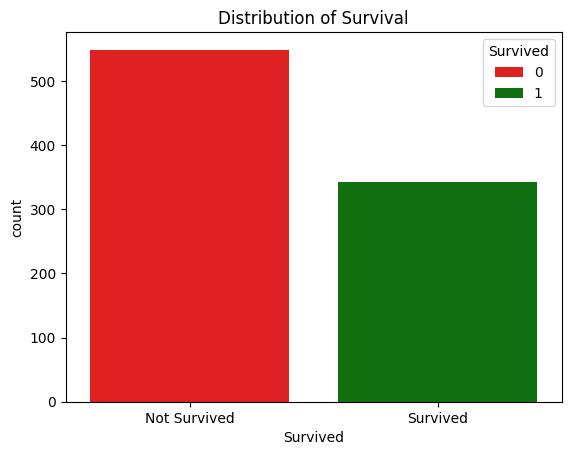

In [ ]:
# Visualize the distribution of the Survived variable

import seaborn as sns
import matplotlib.pyplot as plt

# Plot class distribution
sns.countplot(x='Survived', hue='Survived', data=df, palette=["red", "green"])
plt.xticks([0, 1], ["Not Survived", "Survived"])
plt.title("Distribution of Survival")
plt.show()

In [ ]:
# Count Passengers in Each Class

print(df["Pclass"].value_counts())

Pclass
3    491
1    216
2    184
Name: count, dtype: int64


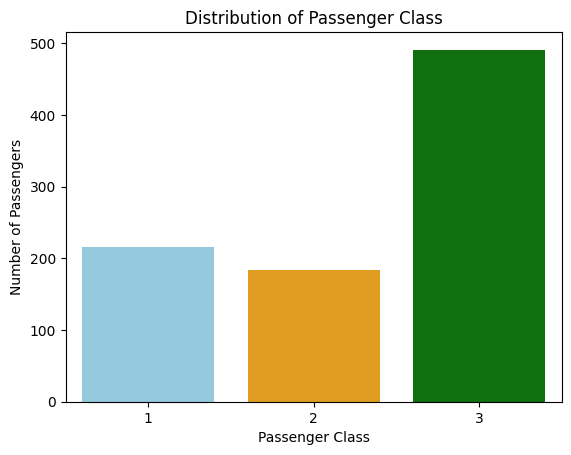

In [ ]:
# Visualize Pclass Distribution

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(
    x="Pclass",
    hue="Pclass",
    data=df,
    palette=["skyblue", "orange", "green"],
    legend=False
)

plt.title("Distribution of Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.show()

In [ ]:
# Identify Which Class Had the Most Passengers

most_passengers = df["Pclass"].mode()[0]
print("Passenger Class with the Most Passengers:", most_passengers)

Passenger Class with the Most Passengers: 3


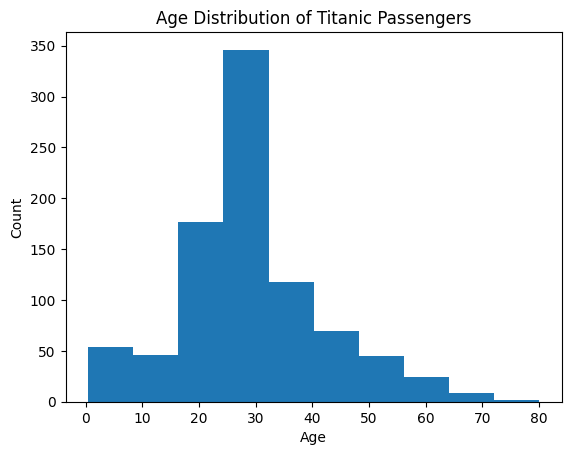

In [ ]:
# Visualize Age distribution

import seaborn as sns
import matplotlib.pyplot as plt


plt.hist(df['Age'], bins=10)
plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

## Task 4: Bivariate and Multivariate Analysis
Bivariate analysis explores the relationship between two variables, specifically focusing on how other features relate to the target variable (Survived).



### Survival by Sex:
```
Create a crosstabulation (or a grouped count) to show the count of survivors and non-survivors grouped by Sex.

Visualize this relationship using a stacked bar chart or a grouped count plot.

Question: Which gender had a significantly higher survival rate?
```

### Survival by Class (Pclass):
```
Calculate and visualize the survival rate for each Pclass.

Question: Is there a clear correlation between ticket class and survival probability?
```


### Survival by Age:
```
Plot and compare the age distribution of survivors vs. non-survivors.

Observation: What does the plot suggest about the survival chances of children and the elderly?
```


### Survival by Port of Embarkation (Embarked):
```
Calculate and visualize the survival rate for each Embarked port.
```

In [ ]:
# Crosstabulation

import pandas as pd

survival_by_sex = pd.crosstab(df["Sex"], df["Survived"])
print(survival_by_sex)

Survived    0    1
Sex               
female     81  233
male      468  109


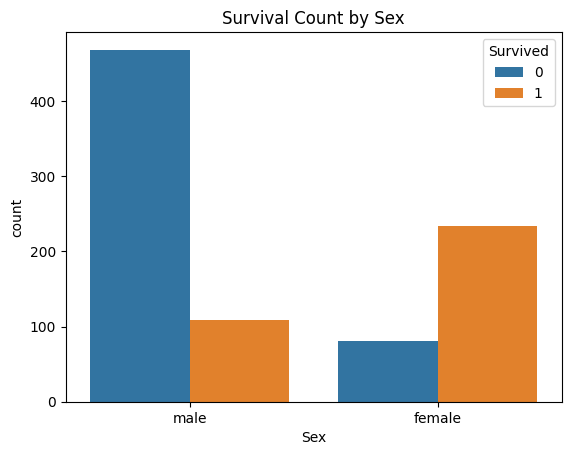

In [ ]:
# Visualization (Grouped Count Plot)

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Sex', hue='Survived', data=df)
plt.title('Survival Count by Sex')
plt.show()

**Question:** Which gender had a significantly higher survival rate?




**Answer:** Female passengers had a significantly higher survival rate than male passengers.


In [ ]:
# Calculate Survival Rate

survival_rate_class = df.groupby("Pclass")["Survived"].mean() * 100
print(survival_rate_class)

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


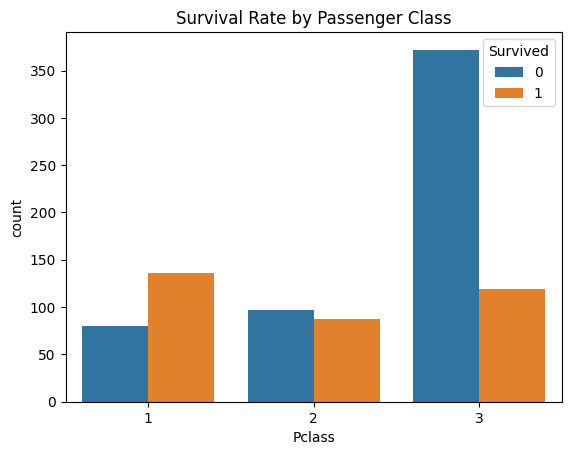

In [ ]:
# Visualization

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Pclass', hue='Survived', data=df)
plt.title('Survival Rate by Passenger Class')
plt.show()

**Question**:

Is there a clear correlation between ticket class and survival probability?

**Answer:**

Yes, there is a clear correlation between ticket class and survival probability.

Passengers in First Class had the highest survival rate, while passengers in Third Class had the lowest survival rate.

A likely reason is that First Class passengers were generally accommodated on the upper decks, which were closer to the lifeboats and evacuation points. This made it easier for them to access lifeboats during the emergency. In contrast, many Third Class passengers were located on the lower decks, farther from the lifeboats, and faced more difficulties reaching the evacuation areas in time.

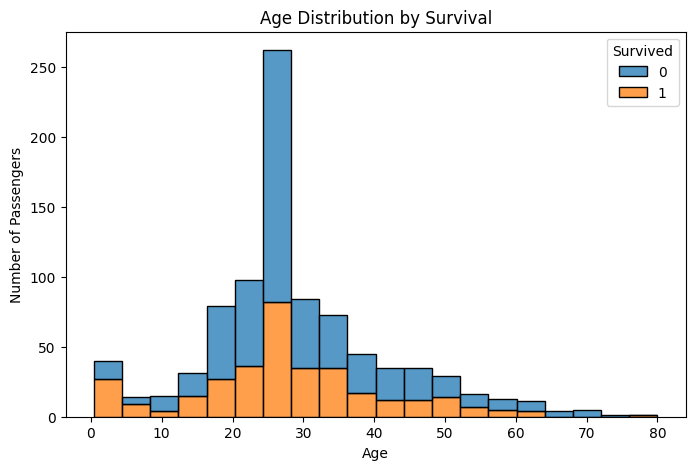

In [ ]:
# Survival by Age

plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Age",
    hue="Survived",
    bins=20,
    multiple="stack"
)

plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

### Observation

The histogram suggests that:

Children had relatively higher survival chances.
Adults had mixed survival outcomes.
Elderly passengers generally had lower survival rates.

Overall, younger passengers appear to have had better survival opportunities than older passengers.

In [ ]:
# Survival by Port of Embarkation (Embarked)
# Calculate Survival Rate

survival_port = df.groupby("Embarked")["Survived"].mean() * 100
print(survival_port)

Embarked
C    55.357143
Q    38.961039
S    33.900929
Name: Survived, dtype: float64


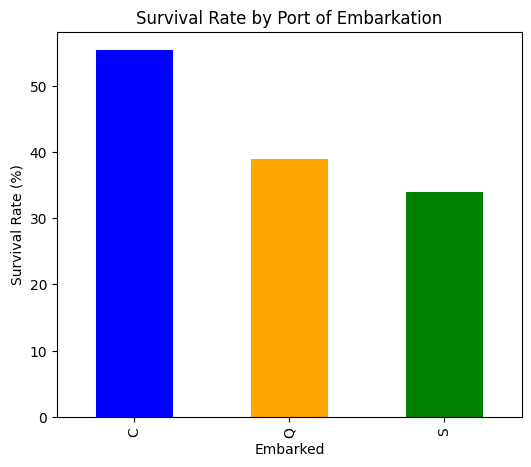

In [ ]:
# Visualization

plt.figure(figsize=(6,5))

survival_port.plot(
    kind="bar",
    color=["blue","orange","green"]
)

plt.title("Survival Rate by Port of Embarkation")
plt.xlabel("Embarked")
plt.ylabel("Survival Rate (%)")

plt.show()

## Task 5: Conclusion and Insights
The Exploratory Data Analysis (EDA) shows that **Sex, Passenger Class, and Age** were the most important factors affecting survival on the Titanic. **Female passengers** had a much higher survival rate than male passengers. **First Class passengers** were more likely to survive than those in Third Class, likely because they had easier access to lifeboats and evacuation areas. The analysis also suggests that **children had better survival chances**, while older passengers generally had lower survival rates. Therefore, **Sex, Pclass, and Age** appear to be the strongest predictors of survival in the Titanic dataset.

